# Transformation Equations:  LSST DP2 <--> EUCLID Q1

_Douglas L. Tucker, Christina L. Adair, Meagan N. Porter_

_2026.08.26_

## 1. Import Modules

In [1]:
import numpy as np
import pandas as pd

from lsst.daf.butler import Butler
import lsst.geom as geom

import pyvo
from pyvo import registry

import os
import time
import sys
import glob
import math
import datetime
import re
import warnings

import pickle

from tqdm.notebook import tqdm

from collections import OrderedDict as odict

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy.units import UnitsWarning
import astropy.units as u

import fitsio

from scipy import interpolate
from scipy.optimize import leastsq

import healpy as hp

import plotly
from plotly.offline import download_plotlyjs, plot, iplot
import plotly.graph_objs as go

from IPython.display import Markdown, display

from mocpy import MOC

import matplotlib.pyplot as plt

%matplotlib inline

## 2. Input Parameters

In [2]:
# LSST-->EUCLID (toLSST=False) or EUCLID-->LSST (toLSST=True)...
#toLSST = True
toLSST = False

if toLSST:
    # List of LSST bands on which to run the transform fit...
    bandList = ['g_LSST', 'r_LSST', 'i_LSST', 'z_LSST', 'y_LSST']
    # If Euclid-->LSST, then the mag and color to fit against are LSST...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'g_LSST':'VIS_EUCLID', 'r_LSST':'VIS_EUCLID', 'i_LSST':'VIS_EUCLID', 'z_LSST':'Y_EUCLID', 'y_LSST':'Y_EUCLID'}
    # Color to fit against...
    color_name_1_dict = {'g_LSST':'VISY_EUCLID', 'r_LSST':'VISY_EUCLID', 'i_LSST':'VISY_EUCLID', 'z_LSST':'VISY_EUCLID', 'y_LSST':'VISY_EUCLID'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'g_LSST':'$(VIS-Y)_{Euclid}$', 'r_LSST':'$(VIS-Y)_{Euclid}$', 'i_LSST':'$(VIS-Y)_{Euclid}$', 'z_LSST':'$(VIS-Y)_{Euclid}$', 'y_LSST':'$(VIS-Y)_{Euclid}$'}
    # Color limits defining disjoint branches of the dmag vs. color plots
    #  (each branch will be fit separately)...
    color_limits_1_dict = {'g_LSST':[-10.,0.4,0.8,10.], 
                           'r_LSST':[-10.,0.8,1.4,10.], 
                           'i_LSST':[-10.,1.15,10.],
                           'z_LSST':[-10.,0.6,1.25,10.],
                           'y_LSST':[-10.,0.6,10.]}

else:
    # List of EUCLID bands on which to run the transform fit...
    bandList = ['VIS_EUCLID', 'Y_EUCLID', 'H_EUCLID', 'J_EUCLID', ]
    #bandList = ['VIS_EUCLID' ]
    # If DES-->Stetson, then the mag and color to fit against are DES...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'VIS_EUCLID':'r_LSST', 'Y_EUCLID':'y_LSST', 'H_EUCLID':'y_LSST', 'J_EUCLID':'y_LSST'}
    # Color to fit against...
    color_name_1_dict = {'VIS_EUCLID':'gi_LSST', 'Y_EUCLID':'zy_LSST', 'H_EUCLID':'zy_LSST', 'J_EUCLID':'zy_LSST'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'VIS_EUCLID':'$(g-i)_{LSST}$', 'Y_EUCLID':'$(z-y)_{LSST}$', 'H_EUCLID':'$(z-y)_{LSST}$', 'J_EUCLID':'$(z-y)_{LSST}$'}
    # Color limits defining disjoint branches of the dmag vs. color plots
    #  (each branch will be fit separately)...    
    color_limits_1_dict = {'VIS_EUCLID':[-10.,1.9,10.], 
                           'Y_EUCLID':[-10., 10.], 
                           'H_EUCLID':[-10., 0.1, 10.],
                           'J_EUCLID':[-10., 0.1, 10.]}



# Order of polynomial fits...
norder = 2

# Sigma-clipping parameters...
nsigma = 3.0
niter = 3

# LSST data
collection = 'LSSTCam/runs/DRP/DP2'
repo = 'dp2_prep'
skymap = 'lsst_cells_v2'
instrument = 'LSSTCam'

# EUCLID data
euclid_tap_url = 'https://eas.esac.esa.int/tap-server/tap'

#Aitoff file
aitoffPlotFileName = 'EUCLID_Q1_LSST_DP2.png'

# Euclid Q1 sky coverage region files downloaded from https://www.euclid-ec.org/science/q1/q1-region-maps/
euclid_q1_region_files = ["q1_edfs.reg", "q1_edff.reg", "q1_edfn.reg"]

#use match file?
useMatchFile = True

# Name of the match file
matchFile = './match_LSST_DP2_Euclid_Q1.csv'

# Base name of QA plot output files...
if toLSST:
    qaFileBaseName = 'qaPlot.Euclid_Q1_to_LSST_DP2.fit'
else:
    qaFileBaseName = 'qaPlot.LSST_DP2_to_Euclid_Q1.fit'

# Directory for cached Euclid Q1 parquet files
cache_dir = "/home/c/cadair/DATA/EuclidQ1_LSSTDP2"
# Create cache_dir directory if it doesn't exist
os.makedirs(cache_dir, exist_ok=True)

# Write a Markdown-formatted summary table of the fits?
write_md_file = True
if write_md_file:
    # Auto-name the .md file based on qaFileBaseName
    md_filename = f"{qaFileBaseName}.qa_summary.md"

# Verbosity level (0, 1, 2, 3, ...)
verbose = 2


## 3. Define Useful Functions

In [3]:
# Useful class to stop "Run All" at a cell 
#  containing the command "raise StopExecution"
class StopExecution(Exception):
    def _render_traceback_(self):
        pass

In [4]:
def cross_match_catalogs(df1, df2, ra_name_1, dec_name_1, ra_name_2, dec_name_2):

    # Create SkyCoord objects for both dataframes
    coords1 = SkyCoord(ra=df1[ra_name_1].values*u.degree, 
                       dec=df1[dec_name_1].values*u.degree)

    coords2 = SkyCoord(ra=df2[ra_name_2].values*u.degree, 
                       dec=df2[dec_name_2].values*u.degree)

    # Match coordinates
    max_sep = 3 * u.arcsec  # Maximum separation
    idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

    # Create mask for matches within max_sep
    mask = d2d < max_sep

    # Create a new dataframe with matches
    matches = df1[mask].copy()
    matches['match_idx'] = idx[mask]  # Index of matching object in df2
    matches['separation_arcsec'] = d2d[mask].arcsec  # Separation in arcseconds

    # Add columns from df2 for the matches
    for col in df2.columns:
        matches[f'match_{col}'] = df2.loc[idx[mask], col].values

    # If multiple matches exist for the same source in df1, keep only the closest one
    matches = matches.loc[matches.groupby(matches.index)['separation_arcsec'].idxmin()]

    # If you want to see which objects in df1 had no matches:
    unmatched = df1[~mask]

    return matches, unmatched

In [5]:
def transform1ColorQAPlots1a(dmag, color1, res, norder, title, plot1Text, dmagName, colorLabel1, rms, outputFileName):

    # Prepare QA plots...
    #fig = plt.figure(figsize=(10,5))
    #fig = plt.figure(figsize=(40,20))
    fig = plt.figure(figsize=(20,10))
    fig.subplots_adjust(hspace=0.3)
    #fig.suptitle("This is a supertitle!")
    plt.rcParams.update({'font.size': 24})

    
    # We will exclude the lowest and highets 0.01% of color1, color2, 
    #  dmag, and residuals when plotting the QA figures...
    color1_desc = color1.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    dmag_desc = dmag.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    #res_desc = df.res.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    res_desc = res.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    #color1_min = color1_desc['1%']
    #color1_max = color1_desc['99%']
    #color1_min = color1_desc['min']
    #color1_max = color1_desc['max']
    #dmag_min = dmag_desc['1%']
    #dmag_max = dmag_desc['99%']
    #res_min = res_desc['1%']
    #res_max = res_desc['99%']
    color1_min = color1_desc['0.01%']
    color1_max = color1_desc['99.99%']
    dmag_min = dmag_desc['0.01%']
    dmag_max = dmag_desc['99.99%']
    res_min = res_desc['0.01%']
    res_max = res_desc['99.99%']
    # What the heck; let's just set this to -0.10 mag --> +0.10 mag...
    #res_min = -0.10
    #res_max = +0.10

    
    # Plot 1:  Descriptive text...
    #plt.subplot(231)
    plt.subplot(221)
    plt.text(0.1,0.80,title,fontsize=24)
    plt.text(0.00,0.40,plot1Text,fontsize=12)
    plt.axis('off')

    
    # Plot 2:  2D hexbin histogram of dmag vs. color1...
    #plt.subplot(232) 
    plt.subplot(222)
    if len(dmag) < 1000:
        plt.scatter(color1, dmag, alpha=0.75)
        #hb=plt.hexbin(color1, dmag, gridsize=100, cmap='inferno_r')
    else:
        hb=plt.hexbin(color1, dmag, gridsize=100, bins='log', cmap='inferno')
    plt.axis([color1_min, color1_max, dmag_min, dmag_max])
    plt.xlabel(colorLabel1)
    plt.ylabel(dmagName)
    if len(dmag) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)


    # Plot 3:  1d histogram of residuals...
    #plt.subplot(234) 
    plt.subplot(223) 
    #plt.hist(df.loc[:,'res'],bins=100)
    if len(res) < 100:
        plt.hist(res,bins=10)
    else:
        plt.hist(res,bins=100)
    plt.xlabel('residuals [mag]')
    plt.ylabel('Number')
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot 4:  2d hexbin histogram of residuals vs. color1...
    #plt.subplot(235) 
    plt.subplot(224)
    if len(res) < 1000:
        plt.scatter(color1, res, alpha=0.75)
        #hb = plt.hexbin(color1, res, gridsize=100, cmap='inferno_r')
    else:
        hb = plt.hexbin(color1, res, gridsize=100, bins='log', cmap='inferno')
    plt.axis([color1_min, color1_max, res_min, res_max])
    plt.xlabel(colorLabel1)
    plt.ylabel('residuals [mag]')
    if len(res) >= 1000:
        cb = plt.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot...
    plt.tight_layout()
    #plt.show()
    plt.savefig(outputFileName)

    return 0


##################################


In [6]:
# Kudos to Claude-3.5-Sonnet for improving on old outlier rejection code...

def poly_fit_with_sigma_clip(x, y, degree=1, sigma=3.0, maxiters=5):
    """
    Perform polynomial fit with iterative sigma clipping
    
    Parameters:
    -----------
    x : array-like
        Independent variable
    y : array-like 
        Dependent variable
    degree : int
        Degree of polynomial fit
    sigma : float
        Sigma clipping threshold
    maxiters : int
        Maximum number of sigma clipping iterations
        
    Returns:
    --------
    coeffs : array
        Polynomial coefficients
    mask : array
        Boolean mask indicating non-clipped points
    rms : float
        RMS of residuals
    """

    # Import relevant modules
    import numpy as np
    from astropy.stats import sigma_clip
    
    # Initial fit using all points
    x = np.asarray(x)
    y = np.asarray(y)
    mask = np.ones_like(x, dtype=bool)
    
    for _ in range(maxiters):
        print(len(x[mask]), len(y[mask]), len(mask))

        # Fit polynomial to non-masked points
        coeffs, cov = np.polyfit(x[mask], y[mask], degree, cov=True)
        
        # Calculate residuals
        yfit = np.polyval(coeffs, x)
        residuals = y - yfit
        
        # Update mask with sigma clipping
        new_mask = ~sigma_clip(residuals, sigma=sigma).mask
        
        # Check for convergence
        if np.array_equal(mask, new_mask):
            break
        
        mask = new_mask
    
    # Calculate final RMS
    final_residuals = y[mask] - np.polyval(coeffs, x[mask])
    rms = np.sqrt(np.mean(final_residuals**2))

    print(len(x[mask]), len(y[mask]), len(mask))

    # Calculate coefficient errors from diagonal of covariance matrix
    coeff_errors = np.sqrt(np.diag(cov))
        
    return coeffs, coeff_errors, x[mask], y[mask], final_residuals, rms

In [7]:
# Kudos to Copilot ChatGPT-5 for these functions for generating Markdown output 
#  of the fit equations...
# See:  https://copilot.microsoft.com/shares/Nopgin8hutEqEmjqJkteY

def latexify_label(label: str) -> str:
    """Strip $ and convert underscores to LaTeX subscripts."""
    label = label.strip('$')
    return re.sub(r'_(\w+)', r'_{\1}', label)

def latexify_name(name: str) -> str:
    """Convert underscores in names to LaTeX subscripts."""
    return re.sub(r'_(\w+)', r'_{\1}', name)

def make_eq_str(dmagName, p_branch, colorLabel_1, norder):
    """
    Build a LaTeX-formatted transformation equation for Markdown.
    Ensures all terms are inside a single $...$ block with proper signs.
    """
    label = latexify_label(colorLabel_1)           # e.g., (g-i)_{LSST}
    dmagName_math = latexify_name(dmagName)        # e.g., U - u_{LSST}

    terms = []
    power = norder
    for coeff in p_branch:
        if power == 0:
            # Constant term: no variable
            terms.append(f"{coeff:+.3f}")
        elif power == 1:
            # Linear term
            terms.append(f"{coeff:+.3f} {label}")
        else:
            terms.append(f"{coeff:+.3f} {label}^{power}")
            # Higher-order term
        power -= 1

    # Join all terms with spaces; signs are already included in coeff formatting
    eq_body = " ".join(terms)
    return f"${dmagName_math} = {eq_body}$"

def make_range_str(color_limits, colorLabel_1, ibranch):
    label = latexify_label(colorLabel_1)
    # Use LaTeX \leq for "less than or equal to"
    return (f"${color_limits[ibranch]:.2f} < {label} \\leq "
            f"{color_limits[ibranch+1]:.2f}$")

def make_output_filename(base, magName, magName_match, color_name_1, norder):
    return f"{base}.dmag_{magName}-{magName_match}.{color_name_1}.norder{norder}.qa1.png"


In [8]:
# Kudos to Copilot ChatGPT-5 for improving the plot text generation

def make_plot_text(dmagName, p_branch, colorLabel_1, norder,
                   color_limits, ibranch, stddev_branch):
    """
    Build a descriptive text string for plots, valid for any polynomial order.
    Example output:
    "g - r = -0.041 -0.302*(g-i)   [0.2 < (g-i) <= 2.5]   [rms: 0.022]"
    """
    terms = []
    power = norder
    for coeff in p_branch:
        if power == 0:
            # Constant term, but still include sign
            terms.append(f"{coeff:+.3f}")
        elif power == 1:
            terms.append(f"{coeff:+.3f}*{colorLabel_1}")
        else:
            terms.append(f"{coeff:+.3f}*{colorLabel_1}^{power}")
        power -= 1

    poly_str = " ".join(terms)

    lo = color_limits[ibranch]
    hi = color_limits[ibranch+1]
    range_str = f"[{lo:.2f} < {colorLabel_1} <= {hi:.2f}]"
    rms_str = f"[rms: {stddev_branch:.3f}]"

    return f"{dmagName} = {poly_str}  {range_str}  {rms_str}"


In [9]:
def tract_bounds(tract):
    poly = tract_polygon(tract)
    ra = np.array([p[0] for p in poly])
    dec = np.array([p[1] for p in poly])
    return ra.min(), ra.max(), dec.min(), dec.max()

In [10]:
def load_ds9_polygons(filename):
    """
    Parse DS9 region file and return list of polygons,
    each polygon = list of (RA, Dec) tuples in degrees.
    """
    polygons = []
    poly_re = re.compile(r"polygon\((.*?)\)")

    with open(filename, "r") as f:
        for line in f:
            m = poly_re.search(line)
            if not m:
                continue
            nums = m.group(1).split(",")
            nums = [float(x.strip()) for x in nums]
            # DS9 polygon format: ra1, dec1, ra2, dec2, ...
            poly = list(zip(nums[0::2], nums[1::2]))
            polygons.append(poly)

    return polygons

In [11]:
def polygon_to_moc(poly):
    ra = np.array([p[0] for p in poly]) * u.deg
    dec = np.array([p[1] for p in poly]) * u.deg
    return MOC.from_polygon(ra, dec)


In [12]:
def tract_polygon(tract):
    poly = tract.getOuterSkyPolygon()
    verts = poly.getVertices()
    return [(geom.SpherePoint(v).getRa().asDegrees(),
            geom.SpherePoint(v).getDec().asDegrees())
            for v in verts]


In [13]:
def tract_moc(tract):
    ra_list, dec_list = zip(*tract_polygon(tract))
    ra = np.array(ra_list) * u.deg
    dec = np.array(dec_list) * u.deg
    return MOC.from_polygon(ra, dec)

In [14]:
# ------------------------------------------------------------
# Helper: tract vertices in RA/Dec
# ------------------------------------------------------------
def tract_vertices(tractId, skymap):
    tract = skymap.generateTract(tractId)
    verts = tract.getVertexList()
    return [(v.getRa().asDegrees(), v.getDec().asDegrees()) for v in verts]

In [15]:
# ------------------------------------------------------------
# Helper: retry logic for slow Euclid TAP service
# ------------------------------------------------------------
def run_query_with_retry(service, query, retries=5):
    for attempt in range(retries):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", UnitsWarning)
                return service.run_sync(query)
        except Exception as e:
            if attempt == retries - 1:
                raise
            time.sleep(2 ** attempt)  # exponential backoff

## X. Read in Matched Catalog

In [16]:
## Check to make sure matchFile exists...
if useMatchFile:
    if os.path.isfile(matchFile)==False:
        print("""ERROR:  matchFile %s does not exist...""" % (matchFile))
    if verbose > 0:
        print('matchFile: ', matchFile)


matchFile:  ./match_LSST_DP2_Euclid_Q1.csv


In [17]:
if useMatchFile:
    tab = Table.read(matchFile, format='csv')
    display(tab)

tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,u_cModelFluxErr,u_extendedness,u_psfFlux_flag,g_psfFlux,g_psfFluxErr,g_ap12Flux,g_ap12FluxErr,g_cModelFlux,g_cModelFluxErr,g_extendedness,g_psfFlux_flag,r_psfFlux,r_psfFluxErr,r_ap12Flux,r_ap12FluxErr,r_cModelFlux,r_cModelFluxErr,r_extendedness,r_psfFlux_flag,i_psfFlux,i_psfFluxErr,i_ap12Flux,i_ap12FluxErr,i_cModelFlux,i_cModelFluxErr,i_extendedness,i_psfFlux_flag,z_psfFlux,z_psfFluxErr,z_ap12Flux,z_ap12FluxErr,z_cModelFlux,z_cModelFluxErr,z_extendedness,z_psfFlux_flag,y_psfFlux,y_psfFluxErr,y_ap12Flux,y_ap12FluxErr,y_cModelFlux,y_cModelFluxErr,y_extendedness,y_psfFlux_flag,match_idx,separation_arcsec,match_OBJECT_ID,match_RIGHT_ASCENSION,match_DECLINATION,match_FLUX_VIS_PSF,match_FLUXERR_VIS_PSF,match_FLUX_VIS_1FWHM_APER,match_FLUXERR_VIS_1FWHM_APER,match_FLUX_VIS_2FWHM_APER,match_FLUXERR_VIS_2FWHM_APER,match_FLUX_VIS_3FWHM_APER,match_FLUXERR_VIS_3FWHM_APER,match_FLUX_VIS_4FWHM_APER,match_FLUXERR_VIS_4FWHM_APER,match_FLUX_Y_1FWHM_APER,match_FLUXERR_Y_1FWHM_APER,match_FLUX_Y_2FWHM_APER,match_FLUXERR_Y_2FWHM_APER,match_FLUX_Y_3FWHM_APER,match_FLUXERR_Y_3FWHM_APER,match_FLUX_Y_4FWHM_APER,match_FLUXERR_Y_4FWHM_APER,match_FLUX_J_1FWHM_APER,match_FLUXERR_J_1FWHM_APER,match_FLUX_J_2FWHM_APER,match_FLUXERR_J_2FWHM_APER,match_FLUX_J_3FWHM_APER,match_FLUXERR_J_3FWHM_APER,match_FLUX_J_4FWHM_APER,match_FLUXERR_J_4FWHM_APER,match_FLUX_H_1FWHM_APER,match_FLUXERR_H_1FWHM_APER,match_FLUX_H_2FWHM_APER,match_FLUXERR_H_2FWHM_APER,match_FLUX_H_3FWHM_APER,match_FLUXERR_H_3FWHM_APER,match_FLUX_H_4FWHM_APER,match_FLUXERR_H_4FWHM_APER,match_point_like_prob,match_spurious_flag,match_flag_vis,match_flag_y,match_flag_j,match_flag_h,match_det_quality_flag
int64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,float64,float64,str5,int64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64
2078,57.21747669899303,-50.722152414769184,2078,80,--,--,--,--,--,--,--,True,3717.6704,89.04332,3654.883,224.92404,3899.1174,92.796234,0.0,False,3900.4944,199.92123,4506.152,401.14865,4035.0005,208.7401,0.0,False,4246.0396,78.736084,4669.143,188.99715,4428.8916,82.5322,1.0,False,3879.23,212.32191,4303.7046,434.00986,3972.5745,220.77982,1.0,False,5345.2866,550.809,5826.376,1569.2269,5545.2515,582.1954,0.0,False,24013,0.008047756189957334,-572174802507221527,57.217480200010726,-50.72215270604899,3.3879590034484863,0.028384564444422722,1.726210117340088,0.028364717960357666,3.3762271404266357,0.050991594791412354,4.050724029541016,0.07254379987716675,4.363100528717041,0.09498497098684311,2.640296459197998,0.1377508044242859,5.515280723571777,0.24578598141670227,6.858391761779785,0.34174588322639465,7.508960723876953,0.4345814287662506,3.7966654300689697,0.12205763906240463,7.874547958374023,0.21517883241176605,9.787094116210938,0.2969071865081787,10.775481224060059,0.3780687153339386,4.974870204925537,0.1449090540409088,10.217924118041992,0.24351045489311218,12.833111763000488,0.32392311096191406,14.24038028717041,0.4036371409893036,0.9330010414123535,0,0,0,0,0,0
2078,57.217173441727006,-50.71254719953168,2078,80,--,--,--,--,--,--,--,True,1083.7426,83.69959,850.03705,222.80861,1071.6205,83.923706,0.0,False,2993.5337,198.10017,2893.335,400.10236,3049.3992,202.94794,0.0,False,4523.753,81.480385,4504.8335,202.97217,4544.2563,82.48264,0.0,False,5549.8223,176.02347,4585.884,

In [18]:
if useMatchFile:
    matches = tab.to_pandas()
    display(matches)

,tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,match_FLUXERR_H_3FWHM_APER,match_FLUX_H_4FWHM_APER,match_FLUXERR_H_4FWHM_APER,match_point_like_prob,match_spurious_flag,match_flag_vis,match_flag_y,match_flag_j,match_flag_h,match_det_quality_flag
0,2078,57.217477,-50.722152,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.323923,14.240380,0.403637,0.933001,0,0,0,0,0,0
1,2078,57.217173,-50.712547,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.294322,8.056615,0.375980,0.754174,0,0,0,0,0,0
2,2078,57.191599,-50.705060,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.666642,124.810921,0.726393,0.978980,0,0,0,0,0,0
3,2078,57.250763,-50.701536,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.400649,37.674515,0.471114,0.930179,0,0,0,0,0,0
4,2078,57.236178,-50.690776,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.290241,4.787020,0.377834,0.898441,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111568,5281,53.450965,-26.343191,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.450242,18.008076,2.087327,0.922955,0,0,0,0,0,0
111569,5281,53.433010,-26.340421,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.356146,8.549581,0.452833,0.923914,0,0,0,0,0,0
111570,5281,53.490199,-26.293165,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.373293,27.692022,0.441995,0.987841,0,0,0,0,0,0
111571,5281,53.499310,-26.252665,5281,39,NaN,NaN,NaN,NaN,NaN,...,1.372815,337.954285,1.433218,0.999833,0,0,0,0,0,0


## 4. Query LSST Catalog

### 4.1 Load Butler and skymap

In [19]:
# Create two butlers, one including the skymap.
#  (Creating two should not be necessary, but...)
if not useMatchFile:
    butler = Butler(repo, collections=collection)
    skymap = butler.get("skyMap", skymap="lsst_cells_v2")


### 4.2 Identify Rubin DP2 Tracts that Overlap Euclid Q1 Release

In [20]:
if not useMatchFile:

    # ------------------------------------------------------------
    # Step 1 — Load Euclid Q1 DS9 region file(s)
    # ------------------------------------------------------------

    # Load all three Euclid Q1 fields
    euclid_polys = []
    for fname in euclid_q1_region_files:
        euclid_polys.extend(load_ds9_polygons(fname))

    print(f"Loaded {len(euclid_polys)} Euclid Q1 polygons.")

    # ------------------------------------------------------------
    # Step 2 — Convert Euclid polygons → MOC
    # ------------------------------------------------------------

    euclid_mocs = [polygon_to_moc(poly) for poly in euclid_polys]

    # Union all polygons into one Euclid Q1 MOC
    euclid_q1_moc = euclid_mocs[0]
    for m in euclid_mocs[1:]:
        euclid_q1_moc = euclid_q1_moc.union(m)

    print("Euclid Q1 MOC constructed.")

    # ------------------------------------------------------------
    # Step 3 — Convert DP2 tracts → MOC and intersect
    # ------------------------------------------------------------

    # Get all DP2 tracts that actually have object tables
    refs = list(
        butler.registry.queryDatasets(
            "object",
            collections=[collection],
            findFirst=True
        )
    )
    dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

    # Intersect each tract with Euclid Q1 MOC
    euclid_overlapping_tracts = []

    for tid in dp2_tracts:
        tmoc = tract_moc(skymap[tid])
        intersection = tmoc.intersection(euclid_q1_moc)
        if not intersection.empty():
            euclid_overlapping_tracts.append(tid)

    print(f"Number of DP2 tracts overlapping Euclid Q1: {len(euclid_overlapping_tracts)}")
    print(euclid_overlapping_tracts)



### 4.3 Query Rubin DP2 Objects from Tracts Overlapping Euclid Q1

In [21]:
if not useMatchFile:

    # The geom_tract_list in this case is the list from euclid_overlapping_tracts
    geom_tract_list = euclid_overlapping_tracts

    # Which columns do we want from the LSST DP2 object table
    INCOLS = ["coord_ra", "coord_dec", "tract", "patch"]
    for band in "ugrizy":
        INCOLS += [
            f"{band}_psfFlux", f"{band}_psfFluxErr",
            f"{band}_ap12Flux", f"{band}_ap12FluxErr",
            f"{band}_cModelFlux", f"{band}_cModelFluxErr",
            f"{band}_extendedness", f"{band}_psfFlux_flag"
        ]

    LSST_stars_list = []
    tracts_with_rubin = []

    #for tractId in geom_tract_list:
    #    print(f"Processing LSST tract {tractId},")
    # tqdm progress bar
    for tractId in tqdm(geom_tract_list, desc="Processing LSST tracts"):
        try:
            raw = butler.get(
                "object",
                dataId={"skymap": "lsst_cells_v2", "tract": tractId},
                collections=[collection],
                parameters={"columns": INCOLS}
            ).to_pandas()
        except Exception as e:
            if verbose > 2:  print(f"  No DP2 object table for tract {tractId}: {e}")
            continue

        raw.insert(0, "tractId", tractId)

        # SNR + flag cuts
        sel = (raw["r_psfFlux"] / raw["r_psfFluxErr"] > 5)
        for b in ["g", "r", "i"]:
            sel &= (raw[f"{b}_psfFlux_flag"] == 0)

        LSST = raw[sel]

        # Star selection
        stars = LSST[(LSST["g_extendedness"] < 0.5) &
                     (LSST["r_extendedness"] < 0.5)]

        if verbose > 2:  print(f"  Stars: {len(stars)}")
        if len(stars) == 0:
            continue

        LSST_stars_list.append(stars)
        tracts_with_rubin.append(tractId)

    # --- 4.5 Final LSST star catalog + tract list ---
    if len(LSST_stars_list) == 0:
        raise RuntimeError("No LSST stars found in any overlapping tract.")

    LSST_stars_all = pd.concat(LSST_stars_list, ignore_index=True)
    tract_list = sorted(set(tracts_with_rubin))

    print(f"\nTotal LSST stars: {len(LSST_stars_all)}")
    print("Tracts with BOTH footprint overlap AND Rubin DP2 data:")
    print(tract_list)

    # --- 4.6 table_patches only for tracts with Rubin data ---
    table_patches = pd.DataFrame({
        "tractId": tract_list,
        "vertices_deg": [tract_vertices(t, skymap) for t in tract_list]
    })


In [22]:
if not useMatchFile:
    display(LSST_stars_all)

In [23]:
# Reset the index (which will help avoid problems in the match algorithm later)
if not useMatchFile:
    LSST_stars_all = LSST_stars_all.reset_index(drop=True)

In [24]:
# Reset the index (which will help avoid problems in the match algorithm later)
if not useMatchFile:
    display(LSST_stars_all)

## 5. Query EUCLID Q1 Catalog

In [25]:
# Invoke TAP service to EUCLID Q1 data....
if not useMatchFile:
    euclid_tap = pyvo.dal.TAPService(euclid_tap_url)

In [26]:
# ============================================================
# Optimized Euclid Q1 catalog query for DP2 tracts overlapping Euclid Q1
#   - Uses BOX() geometry (Euclid-compatible)
#   - Tiles each tract bounding box into 0.5° × 0.5° boxes
#   - Retry logic
#   - Batch processing
#   - Per-tract caching
#   - Warning suppression
#   - Includes full VIS/Y/J/H aperture flux set
# ============================================================

if not useMatchFile:

    euclid_tap = pyvo.dal.TAPService(euclid_tap_url)

    # Batch the tract list to avoid long TAP sessions
    def chunk_list(lst, n):
        for i in range(0, len(lst), n):
            yield lst[i:i+n]

    all_results = []

    # Tile size
    ra_step = 1.0
    dec_step = 1.0

    # Process tracts in batches of 10
    for batch in chunk_list(euclid_overlapping_tracts, 10):

        print(f"Processing batch: {batch}")

        for tid in tqdm(batch, desc="Euclid Q1 tract batch"):

            #cache_file = f"euclid_q1_tract_{tid}.parquet"
            cache_file = os.path.join(cache_dir, f"euclid_q1_tract_{tid}.parquet")
            if os.path.exists(cache_file):
                df = pd.read_parquet(cache_file)
                all_results.append(df)
                continue

            tract = skymap[tid]
            ra_min, ra_max, dec_min, dec_max = tract_bounds(tract)

            ra_edges = np.arange(ra_min, ra_max + ra_step, ra_step)
            dec_edges = np.arange(dec_min, dec_max + dec_step, dec_step)

            tract_results = []

            for ra in ra_edges[:-1]:
                for dec in dec_edges[:-1]:

                    ra_center = ra + ra_step / 2
                    dec_center = dec + dec_step / 2

                    query = f"""
                    SELECT
                        OBJECT_ID,
                        RIGHT_ASCENSION,
                        DECLINATION,

                        FLUX_VIS_PSF,
                        FLUXERR_VIS_PSF,

                        FLUX_VIS_1FWHM_APER, FLUXERR_VIS_1FWHM_APER,
                        FLUX_VIS_2FWHM_APER, FLUXERR_VIS_2FWHM_APER,
                        FLUX_VIS_3FWHM_APER, FLUXERR_VIS_3FWHM_APER,
                        FLUX_VIS_4FWHM_APER, FLUXERR_VIS_4FWHM_APER,

                        FLUX_Y_1FWHM_APER, FLUXERR_Y_1FWHM_APER,
                        FLUX_Y_2FWHM_APER, FLUXERR_Y_2FWHM_APER,
                        FLUX_Y_3FWHM_APER, FLUXERR_Y_3FWHM_APER,
                        FLUX_Y_4FWHM_APER, FLUXERR_Y_4FWHM_APER,

                        FLUX_J_1FWHM_APER, FLUXERR_J_1FWHM_APER,
                        FLUX_J_2FWHM_APER, FLUXERR_J_2FWHM_APER,
                        FLUX_J_3FWHM_APER, FLUXERR_J_3FWHM_APER,
                        FLUX_J_4FWHM_APER, FLUXERR_J_4FWHM_APER,

                        FLUX_H_1FWHM_APER, FLUXERR_H_1FWHM_APER,
                        FLUX_H_2FWHM_APER, FLUXERR_H_2FWHM_APER,
                        FLUX_H_3FWHM_APER, FLUXERR_H_3FWHM_APER,
                        FLUX_H_4FWHM_APER, FLUXERR_H_4FWHM_APER,

                        point_like_prob,
                        spurious_flag,
                        flag_vis,
                        flag_y,
                        flag_j,
                        flag_h,
                        det_quality_flag

                    FROM catalogue.mer_catalogue

                    WHERE CONTAINS(
                        POINT('ICRS', RIGHT_ASCENSION, DECLINATION),
                        BOX('ICRS', {ra_center}, {dec_center}, {ra_step}, {dec_step})
                    ) = 1

                    AND (FLUX_VIS_PSF / FLUXERR_VIS_PSF > 5.)
                    AND spurious_flag = 0
                    AND flag_vis = 0 AND flag_y = 0 AND flag_j = 0 AND flag_h = 0
                    AND det_quality_flag IN (0, 2, 512)
                    AND point_like_prob > 0.7
                    """

                    try:
                        result = run_query_with_retry(euclid_tap, query)
                        print(tract, len(result))
                        if len(result) > 0:
                            tract_results.append(result.to_table().to_pandas())
                    except Exception as e:
                        print(f"Error in tract {tid}, ra={ra}, dec={dec}: {e}")
                        continue

            if tract_results:
                df = pd.concat(tract_results, ignore_index=True).drop_duplicates()
            else:
                df = pd.DataFrame()

            df.to_parquet(cache_file)
            all_results.append(df)

    if all_results:
        euclid_q1_df = pd.concat(all_results, ignore_index=True).drop_duplicates()
    else:
        euclid_q1_df = pd.DataFrame()

    print(f"Total Euclid Q1 objects found: {len(euclid_q1_df)}")


In [27]:
# Make a soft copy of euclid_q1_df to combined_df
if not useMatchFile:
    combined_df = euclid_q1_df

In [28]:
# Reset the index (which will help avoid problems in the match algorithm later)
if not useMatchFile:
    combined_df = combined_df.reset_index(drop=True)

In [29]:
if not useMatchFile:
    display(combined_df)

In [30]:
# Sanity check that the two data sets do actually overlap!
if not useMatchFile:
    plt.figure(figsize=(12, 7))
    ax = plt.subplot(111)
    ax.scatter(combined_df.RIGHT_ASCENSION, combined_df.DECLINATION, s=1, alpha=0.5, color="blue")
    ax.scatter(LSST_stars_all.coord_ra, LSST_stars_all.coord_dec, s=1, alpha=0.5, color="red")

## 6. Match LSST and EUCLID stars

In [31]:
if not useMatchFile:
    matches, unmatched = cross_match_catalogs(LSST_stars_all, combined_df, 
                                              'coord_ra', 'coord_dec', 
                                              'RIGHT_ASCENSION', 'DECLINATION')

In [32]:
if not useMatchFile:
    matches.to_csv(matchFile,index=False)

In [33]:
if not useMatchFile:
    display(matches)

In [34]:
if not useMatchFile:
    display(unmatched)

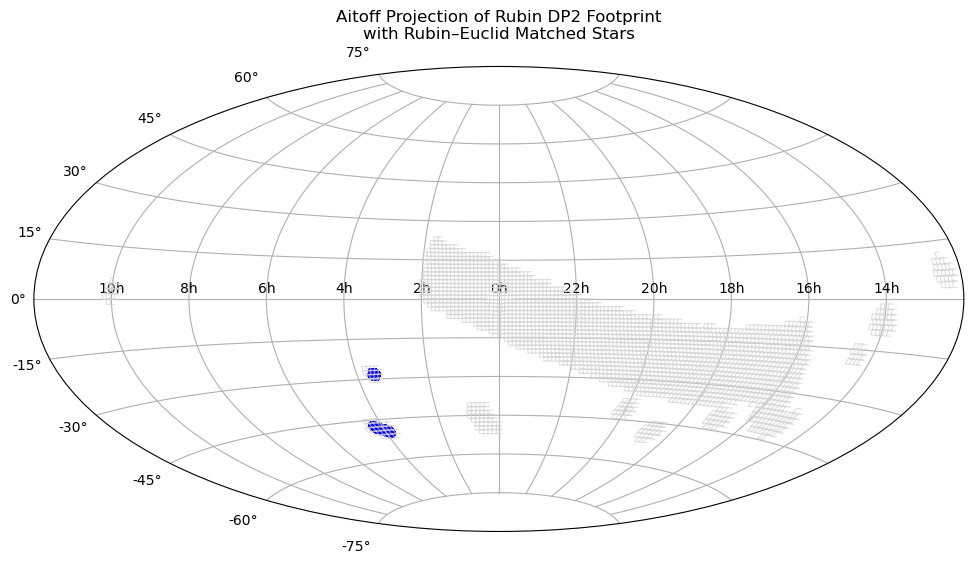

In [35]:
# Plot Aitoff sky plot of new match file...

#if not useMatchFile:
if True:
    
    # ------------------------------------------------------------
    # Extract RA/Dec from your final matches table
    # ------------------------------------------------------------
    ra = matches["coord_ra"].values
    dec = matches["coord_dec"].values

    # Convert RA to [-180, +180] degrees
    ra_wrapped = np.remainder(ra + 180.0, 360.0) - 180.0

    # Convert to radians
    ra_rad = np.deg2rad(-ra_wrapped)
    dec_rad = np.deg2rad(dec)

    # ------------------------------------------------------------
    # Self-contained: find ONLY the tracts that contain DP2 data
    # ------------------------------------------------------------
    _but = Butler(repo, collections=collection)

    # Query all object-table datasets in the DP2 collection
    refs = list(_but.registry.queryDatasets(
        "object",
        collections=[collection],
        findFirst=True
    ))

    # Extract unique tract IDs
    dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

    # Load skymap
    _skymap = _but.get("skyMap", skymap="lsst_cells_v2")

    # Convert tract polygons to RA/Dec
    def _tract_vertices_deg(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()
        ra_list, dec_list = [], []
        for v in verts:
            sp = geom.SpherePoint(v)
            ra_list.append(sp.getRa().asDegrees())
            dec_list.append(sp.getDec().asDegrees())
        return list(zip(ra_list, dec_list))

    # Build list of polygons for DP2 tracts only
    _dp2_vertices = [_tract_vertices_deg(_skymap[tid]) for tid in dp2_tracts]

    # ------------------------------------------------------------
    # Create Aitoff projection
    # ------------------------------------------------------------
    plt.figure(figsize=(12, 7))
    ax = plt.subplot(111, projection="aitoff")

    # ------------------------------------------------------------
    # 1. Plot ONLY Rubin DP2 tracts (not full skymap)
    # ------------------------------------------------------------
    for vertices in _dp2_vertices:
        ra_poly = np.array([v[0] for v in vertices])
        dec_poly = np.array([v[1] for v in vertices])

        # Wrap RA to [-180, +180]
        ra_poly_wrapped = np.remainder(ra_poly + 180.0, 360.0) - 180.0

        # Convert to radians
        ra_poly_rad = np.deg2rad(-ra_poly_wrapped)
        dec_poly_rad = np.deg2rad(dec_poly)

        ax.plot(ra_poly_rad, dec_poly_rad,
                color="lightgray", linewidth=0.8, alpha=0.7)

    # ------------------------------------------------------------
    # 2. Plot matched stars on top
    # ------------------------------------------------------------
    ax.scatter(ra_rad, dec_rad, s=1, alpha=0.5, color="blue")
    #ax.set_xticklabels(['14h','16h','18h','20h','22h','0h','2h','4h','6h','8h','10h'])
    ax.set_xticklabels(['10h','8h','6h','4h','2h','0h','22h','20h','18h','16h','14h'])

    ax.grid(True)
    plt.title("Aitoff Projection of Rubin DP2 Footprint\nwith Rubin–Euclid Matched Stars", pad=20)

    # Save to PNG file
    plt.savefig(aitoffPlotFileName, dpi=200, bbox_inches="tight")

    # Plot to screen
    plt.show()


##  7. Add ABmag Columns to Matched Catalog Data Frame

In [36]:
# Copy matches to df...
df = matches.copy()

In [37]:
# Define common parameters
flux_bands = ['u', 'g', 'r', 'i', 'z', 'y']
offset = 31.4 # For magnitude calculation
sentinel_value = -9999.0

# Loop through each band to calculate both magnitude and magnitude error
for band in flux_bands:
    
    flux_col = f'{band}_psfFlux'
    flux_err_col = f'{band}_psfFluxErr'
    mag_col = f'{band}_psfMag'
    mag_err_col = f'{band}_psfMagErr'

    # Condition for valid flux (must be positive for log10 and division)
    valid_flux_condition = df[flux_col] > 0

    # Calculate magnitude
    df[mag_col] = np.where(valid_flux_condition,
                           -2.5 * np.log10(df[flux_col]) + offset,
                           sentinel_value)

    # Calculate magnitude error
    df[mag_err_col] = np.where(valid_flux_condition,
                               1.086 * df[flux_err_col] / df[flux_col],
                               sentinel_value)



/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/co

In [38]:
df

,tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,g_psfMag,g_psfMagErr,r_psfMag,r_psfMagErr,i_psfMag,i_psfMagErr,z_psfMag,z_psfMagErr,y_psfMag,y_psfMagErr
0,2078,57.217477,-50.722152,2078,80,NaN,NaN,NaN,NaN,NaN,...,22.474323,0.026011,22.422201,0.055663,22.330040,0.020138,22.428136,0.059440,22.080073,0.111908
1,2078,57.217173,-50.712547,2078,80,NaN,NaN,NaN,NaN,NaN,...,23.812685,0.083874,22.709540,0.071867,22.261253,0.019561,22.039302,0.034445,21.800380,0.086869
2,2078,57.191599,-50.705060,2078,80,NaN,NaN,NaN,NaN,NaN,...,23.464760,0.062780,21.973855,0.028983,20.268845,0.003111,19.540818,0.004831,19.160389,0.008340
3,2078,57.250763,-50.701536,2078,80,NaN,NaN,NaN,NaN,NaN,...,23.894112,0.095264,22.682108,0.051729,21.234923,0.007327,20.636076,0.009725,20.321753,0.022326
4,2078,57.236178,-50.690776,2078,80,NaN,NaN,NaN,NaN,NaN,...,22.922658,0.040448,22.555091,0.057505,22.387642,0.018751,22.315118,0.044096,22.220459,0.123802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111568,5281,53.450965,-26.343191,5281,39,NaN,NaN,NaN,NaN,NaN,...,24.338054,0.118757,22.945397,0.030399,21.802458,0.008955,21.328955,0.020276,21.075271,0.083131
111569,5281,53.433010,-26.340421,5281,39,NaN,NaN,NaN,NaN,NaN,...,25.180172,0.255408,24.110394,0.087172,22.673806,0.018694,22.178889,0.039514,21.915023,0.234368
111570,5281,53.490199,-26.293165,5281,39,NaN,NaN,NaN,NaN,NaN,...,22.483596,0.026701,21.310652,0.017412,20.899052,0.004567,20.678490,0.009632,22.601695,0.330291
111571,5281,53.499310,-26.252665,5281,39,NaN,NaN,NaN,NaN,NaN,...,20.570620,0.006865,19.350142,0.006073,18.512728,0.000940,18.147546,0.001812,17.988510,0.005372


In [39]:
# Define common parameters
flux_bands = ['VIS', 'Y', 'J', 'H']
offset = 23.9 # For magnitude calculation
sentinel_value = -9999.0

# Loop through each band to calculate both magnitude and magnitude error
for band in flux_bands:
    flux_col = f'match_FLUX_{band}_4FWHM_APER'
    flux_err_col = f'match_FLUXERR_{band}_4FWHM_APER'
    mag_col = f'match_MAG_{band}_4FWHM_APER'
    mag_err_col = f'match_MAGERR_{band}_4FWHM_APER'

    print(flux_col, flux_err_col, mag_col, mag_err_col)
    # Condition for valid flux (must be positive for log10 and division)
    valid_flux_condition = df[flux_col] > 0

    # Calculate magnitude
    df[mag_col] = np.where(valid_flux_condition,
                           -2.5 * np.log10(df[flux_col]) + offset,
                           sentinel_value)

    # Calculate magnitude error
    df[mag_err_col] = np.where(valid_flux_condition,
                               1.086 * df[flux_err_col] / df[flux_col],
                               sentinel_value)


match_FLUX_VIS_4FWHM_APER match_FLUXERR_VIS_4FWHM_APER match_MAG_VIS_4FWHM_APER match_MAGERR_VIS_4FWHM_APER
match_FLUX_Y_4FWHM_APER match_FLUXERR_Y_4FWHM_APER match_MAG_Y_4FWHM_APER match_MAGERR_Y_4FWHM_APER
match_FLUX_J_4FWHM_APER match_FLUXERR_J_4FWHM_APER match_MAG_J_4FWHM_APER match_MAGERR_J_4FWHM_APER
match_FLUX_H_4FWHM_APER match_FLUXERR_H_4FWHM_APER match_MAG_H_4FWHM_APER match_MAGERR_H_4FWHM_APER


/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [40]:
for col in df.columns:
    print(col)

tractId
coord_ra
coord_dec
tract
patch
u_psfFlux
u_psfFluxErr
u_ap12Flux
u_ap12FluxErr
u_cModelFlux
u_cModelFluxErr
u_extendedness
u_psfFlux_flag
g_psfFlux
g_psfFluxErr
g_ap12Flux
g_ap12FluxErr
g_cModelFlux
g_cModelFluxErr
g_extendedness
g_psfFlux_flag
r_psfFlux
r_psfFluxErr
r_ap12Flux
r_ap12FluxErr
r_cModelFlux
r_cModelFluxErr
r_extendedness
r_psfFlux_flag
i_psfFlux
i_psfFluxErr
i_ap12Flux
i_ap12FluxErr
i_cModelFlux
i_cModelFluxErr
i_extendedness
i_psfFlux_flag
z_psfFlux
z_psfFluxErr
z_ap12Flux
z_ap12FluxErr
z_cModelFlux
z_cModelFluxErr
z_extendedness
z_psfFlux_flag
y_psfFlux
y_psfFluxErr
y_ap12Flux
y_ap12FluxErr
y_cModelFlux
y_cModelFluxErr
y_extendedness
y_psfFlux_flag
match_idx
separation_arcsec
match_OBJECT_ID
match_RIGHT_ASCENSION
match_DECLINATION
match_FLUX_VIS_PSF
match_FLUXERR_VIS_PSF
match_FLUX_VIS_1FWHM_APER
match_FLUXERR_VIS_1FWHM_APER
match_FLUX_VIS_2FWHM_APER
match_FLUXERR_VIS_2FWHM_APER
match_FLUX_VIS_3FWHM_APER
match_FLUXERR_VIS_3FWHM_APER
match_FLUX_VIS_4FWHM_APER
mat

In [41]:
# Rename columns...
df.rename(columns={'coord_ra':'RA_LSST',
                   'coord_dec':'DEC_LSST',
                   'g_psfMag':'g_LSST',
                   'r_psfMag':'r_LSST',
                   'i_psfMag':'i_LSST',
                   'z_psfMag':'z_LSST',
                   'y_psfMag':'y_LSST',
                   'g_psfMagErr':'g_err_LSST',
                   'r_psfMagErr':'r_err_LSST',
                   'i_psfMagErr':'i_err_LSST',
                   'z_psfMagErr':'z_err_LSST',
                   'y_psfMagErr':'y_err_LSST',
                   'match_MAG_VIS_4FWHM_APER':'VIS_EUCLID',
                   'match_MAG_Y_4FWHM_APER':'Y_EUCLID',
                   'match_MAG_J_4FWHM_APER':'J_EUCLID',
                   'match_MAG_H_4FWHM_APER':'H_EUCLID',
                   'match_MAGERR_VIS_4FWHM_APER':'VIS_ERR_EUCLID',
                   'match_MAGERR_Y_4FWHM_APER':'Y_ERR_EUCLID',
                   'match_MAGERR_J_4FWHM_APER':'J_ERR_EUCLID',
                   'match_MAGERR_H_4FWHM_APER':'H_ERR_EUCLID' 
                  },inplace=True)

df.head(5)

,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,y_LSST,y_err_LSST,VIS_EUCLID,VIS_ERR_EUCLID,Y_EUCLID,Y_ERR_EUCLID,J_EUCLID,J_ERR_EUCLID,H_EUCLID,H_ERR_EUCLID
0,2078,57.217477,-50.722152,2078,80,NaN,NaN,NaN,NaN,NaN,...,22.080073,0.111908,22.300512,0.023642,21.711050,0.062852,21.318908,0.038103,21.016196,0.030782
1,2078,57.217173,-50.712547,2078,80,NaN,NaN,NaN,NaN,NaN,...,21.800380,0.086869,22.477556,0.028998,21.539754,0.052526,21.606676,0.052678,21.634618,0.050681
2,2078,57.191599,-50.705060,2078,80,NaN,NaN,NaN,NaN,NaN,...,19.160389,0.008340,20.628003,0.007329,18.870202,0.022582,18.719450,0.009144,18.659369,0.006320
3,2078,57.250763,-50.701536,2078,80,NaN,NaN,NaN,NaN,NaN,...,20.321753,0.022326,21.656813,0.015690,20.211365,0.018327,19.998293,0.014510,19.959881,0.013580
4,2078,57.236178,-50.690776,2078,80,NaN,NaN,NaN,NaN,NaN,...,22.220459,0.123802,22.441497,0.026563,21.987769,0.088595,22.010603,0.072553,22.199837,0.085717


## 8. Add Color Columns to Matched Catalog Data Frame

In [42]:
# Add color columns...
df.loc[:,'gr_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'r_LSST']
df.loc[:,'ri_LSST'] = df.loc[:,'r_LSST'] - df.loc[:,'i_LSST']
df.loc[:,'iz_LSST'] = df.loc[:,'i_LSST'] - df.loc[:,'z_LSST']
df.loc[:,'zy_LSST'] = df.loc[:,'z_LSST'] - df.loc[:,'y_LSST']
df.loc[:,'gi_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'i_LSST']

df.loc[:,'VISY_EUCLID'] = df.loc[:,'VIS_EUCLID'] - df.loc[:,'Y_EUCLID']
df.loc[:,'YH_EUCLID'] = df.loc[:,'Y_EUCLID'] - df.loc[:,'H_EUCLID']
df.loc[:,'HJ_EUCLID'] = df.loc[:,'H_EUCLID'] - df.loc[:,'J_EUCLID']

In [43]:
# Insert dmag column...
df.loc[:,'dmag'] = -9999.

In [44]:
df

,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,H_ERR_EUCLID,gr_LSST,ri_LSST,iz_LSST,zy_LSST,gi_LSST,VISY_EUCLID,YH_EUCLID,HJ_EUCLID,dmag
0,2078,57.217477,-50.722152,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.030782,0.052122,0.092161,-0.098096,0.348064,0.144283,0.589462,0.694854,-0.302712,-9999.0
1,2078,57.217173,-50.712547,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.050681,1.103145,0.448287,0.221950,0.238922,1.551432,0.937802,-0.094864,0.027943,-9999.0
2,2078,57.191599,-50.705060,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.006320,1.490905,1.705010,0.728026,0.380429,3.195915,1.757801,0.210833,-0.060082,-9999.0
3,2078,57.250763,-50.701536,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.013580,1.212004,1.447185,0.598847,0.314322,2.659189,1.445448,0.251484,-0.038412,-9999.0
4,2078,57.236178,-50.690776,2078,80,NaN,NaN,NaN,NaN,NaN,...,0.085717,0.367567,0.167450,0.072524,0.094659,0.535017,0.453729,-0.212068,0.189234,-9999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111568,5281,53.450965,-26.343191,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.125879,1.392658,1.142938,0.473503,0.253684,2.535596,1.248526,0.056183,0.028093,-9999.0
111569,5281,53.433010,-26.340421,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.057521,1.069779,1.436588,0.494917,0.263866,2.506367,1.588030,0.016696,0.036576,-9999.0
111570,5281,53.490199,-26.293165,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.017334,1.172944,0.411600,0.220562,-1.923204,1.584544,0.667477,0.209899,-0.019760,-9999.0
111571,5281,53.499310,-26.252665,5281,39,NaN,NaN,NaN,NaN,NaN,...,0.004606,1.220478,0.837414,0.365182,0.159036,2.057892,1.061856,0.200562,-0.062277,-9999.0


(15.0, 30.0)

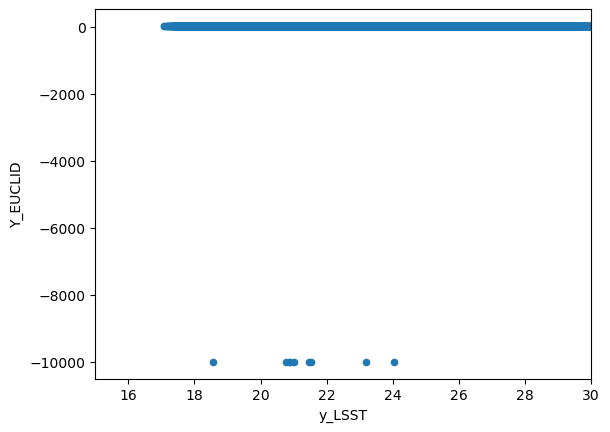

In [45]:
df.plot('y_LSST', 'Y_EUCLID', kind='scatter')
plt.xlim([15,30.])

## 9. Create Initial Mask

In [46]:
mask1 = df["VIS_EUCLID"] > 0.
mask2 = df["Y_EUCLID"] > 0.
mask3 = df["H_EUCLID"] > 0.
mask4 = df["J_EUCLID"] > 0.
mask5 = (df["VIS_ERR_EUCLID"] > 0.00) & (df["VIS_ERR_EUCLID"] <= 0.03)
mask6 = (df["Y_ERR_EUCLID"] > 0.00) & (df["Y_ERR_EUCLID"] <= 0.03)
mask7 = (df["H_ERR_EUCLID"] > 0.00) & (df["H_ERR_EUCLID"] <= 0.03)
mask8 = (df["J_ERR_EUCLID"] > 0.00) & (df["J_ERR_EUCLID"] <= 0.03)
mask_Euclid = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8

mask1 = df["g_LSST"] > 0.
mask2 = df["r_LSST"] > 0.
mask3 = df["i_LSST"] > 0.
mask4 = df["z_LSST"] > 0.
mask5 = df["y_LSST"] > 0.
mask6 = df["g_err_LSST"] <= 0.02
mask7 = df["r_err_LSST"] <= 0.02
mask8 = df["i_err_LSST"] <= 0.02
mask9 = df["z_err_LSST"] <= 0.02
mask10 = df["y_err_LSST"] <= 0.02
mask_LSST = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10

mask = mask_Euclid & mask_LSST

## 10. Make Backup Copies of Initial Mask and Original Data Frame

In [47]:
# Make a backup copy of original df...
df_orig = df.copy()

# Make a backup copy of original mask...
mask_orig = mask.copy()

## 11. Run Fit in Each Filter Band




# # # # # # # # # # # # # # # # # # # # 
VIS_EUCLID
# # # # # # # # # # # # # # # # # # # # 

VIS_EUCLID [-10.0, 1.9, 10.0] 2
VIS_EUCLID [-0.6, 1.9, 3.8] 2
*********************************
0 -0.6 1.9
*********************************
mask_branch length (before): 19280
dmag_branch length: 7911
color1_branch length: 7911
7911 7911 7911
7433 7433 7911
7433 7433 7911
7433 7433 7911
7433 7433 7911
mask_branch length (after): 19280
p_2 = -0.071700 ± 0.001146
p_1 = -0.082803 ± 0.002520
p_0 = 0.062698 ± 0.001151

VIS_EUCLID - r_LSST = 0.063 + -0.083*$(g-i)_{LSST}$ + -0.072*$(g-i)_{LSST}$^2  [-0.21 < $(g-i)_{LSST}$ <= 1.90] [rms: 0.021]
VIS_EUCLID - r_LSST = -0.072*$(g-i)_{LSST}$^2 -0.083*$(g-i)_{LSST}$ +0.063  [-0.21 < $(g-i)_{LSST}$ <= 1.90]  [rms: 0.021]

VIS_EUCLID - r_LSST = -0.072*$(g-i)_{LSST}$^2 -0.083*$(g-i)_{LSST}$ +0.063  [-0.21 < $(g-i)_{LSST}$ <= 1.90]  [rms: 0.021]
*********************************
1 1.8999530836277856 3.8
*********************************
mask_branch length (

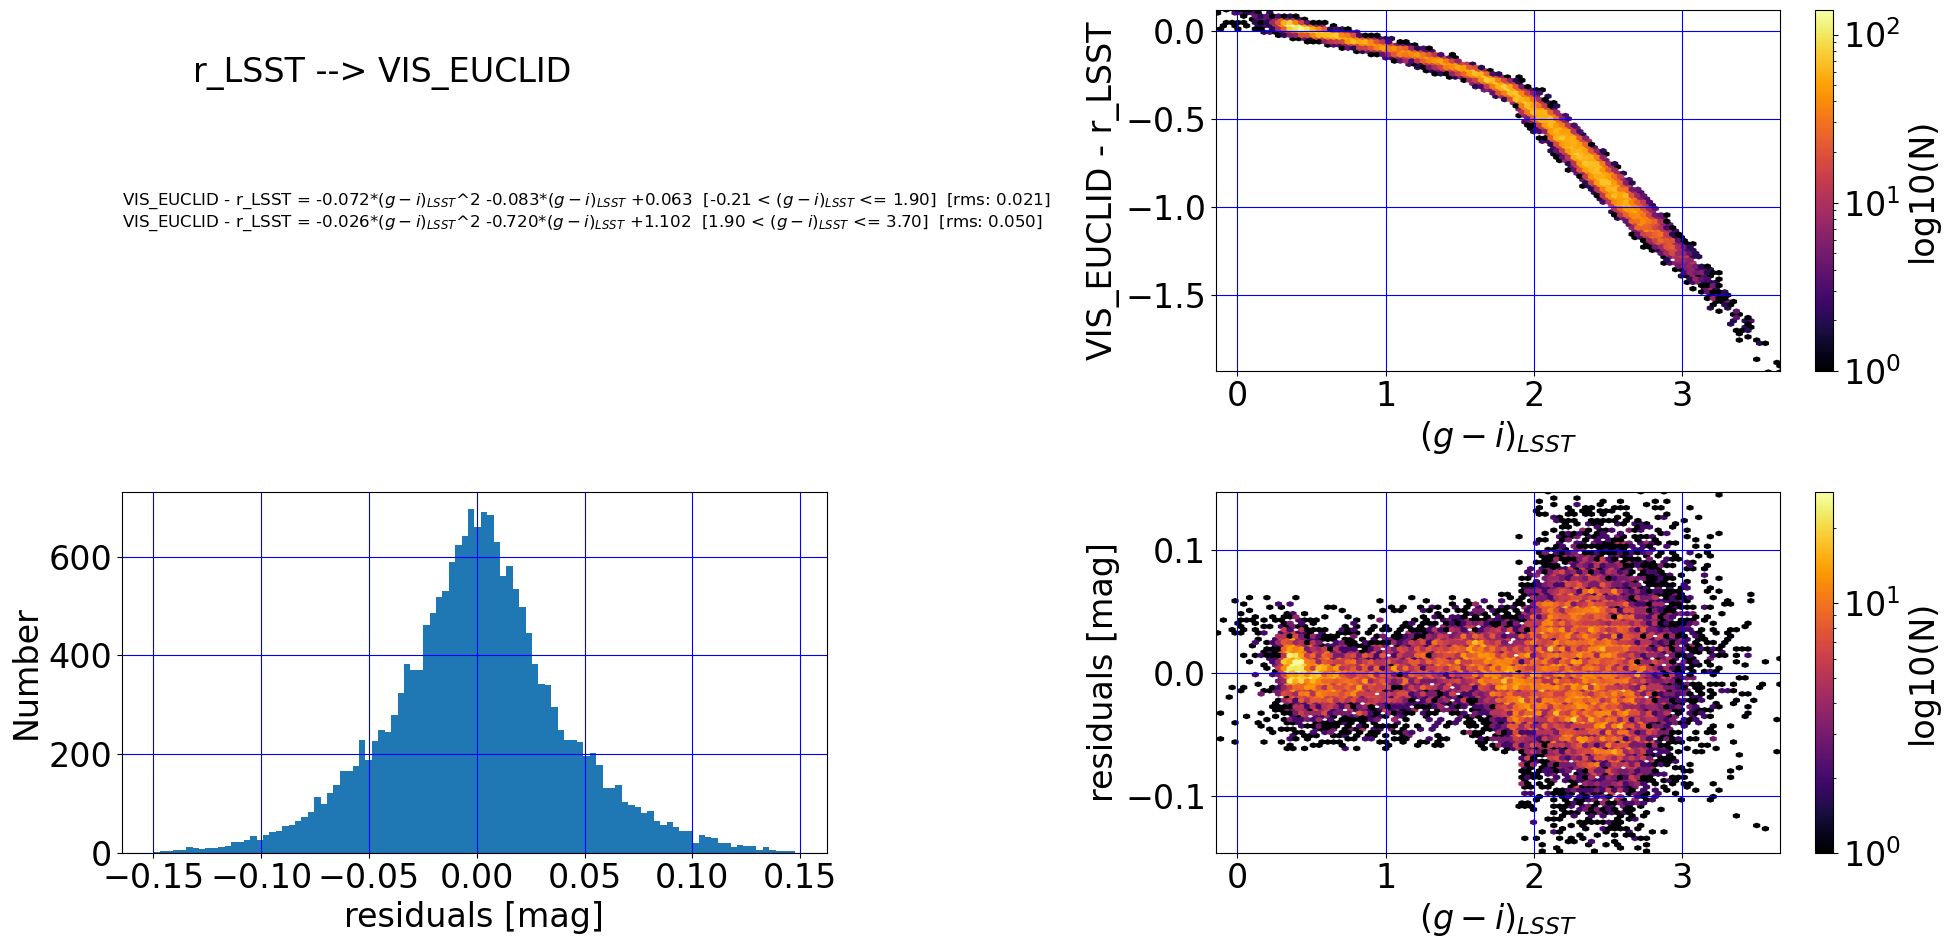

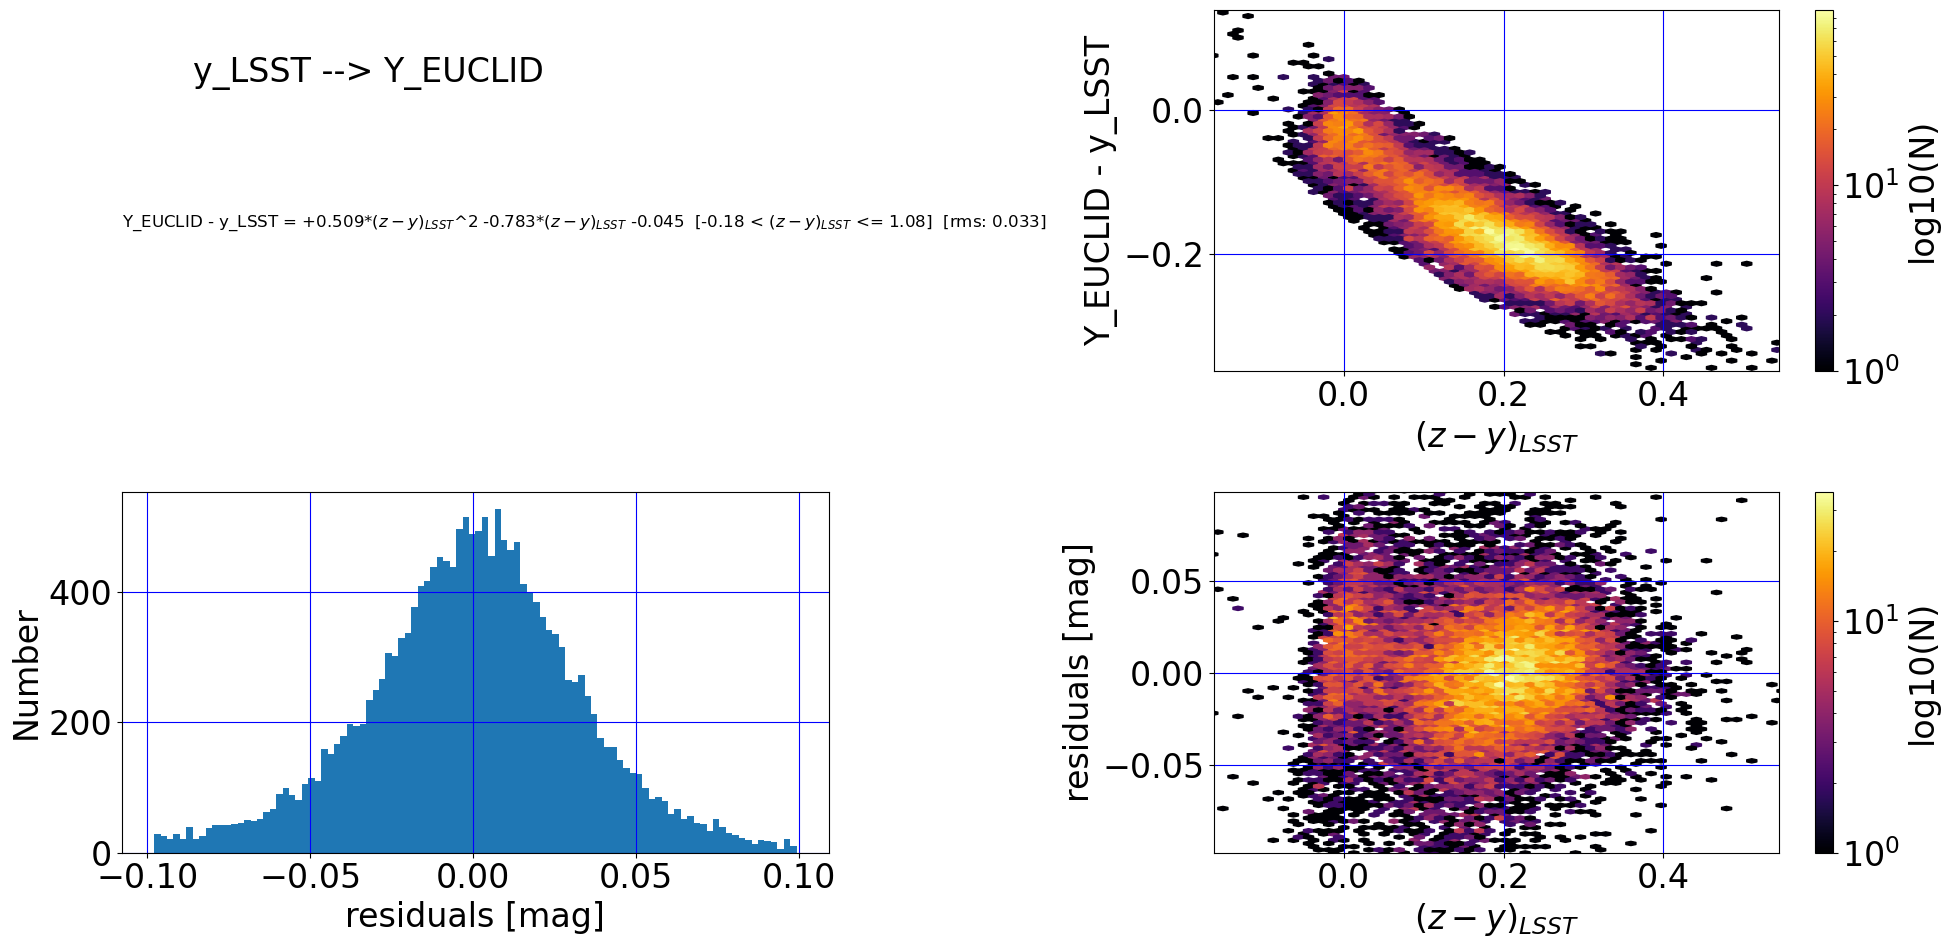

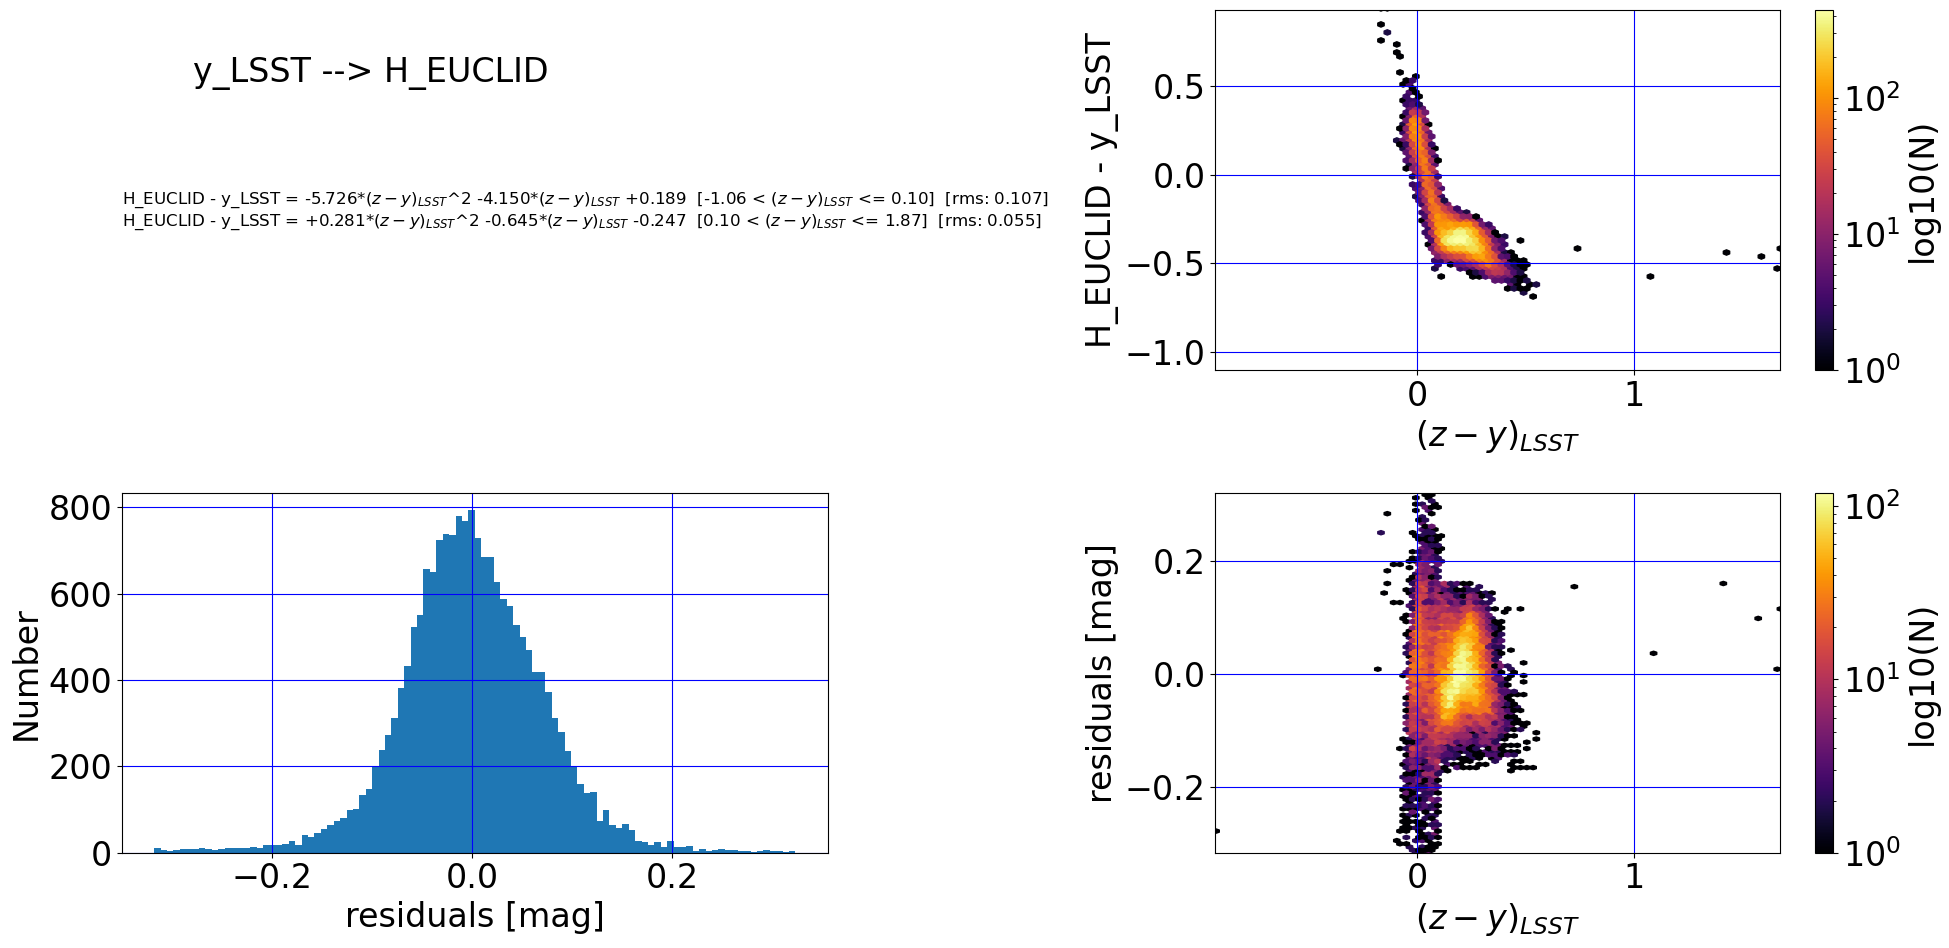

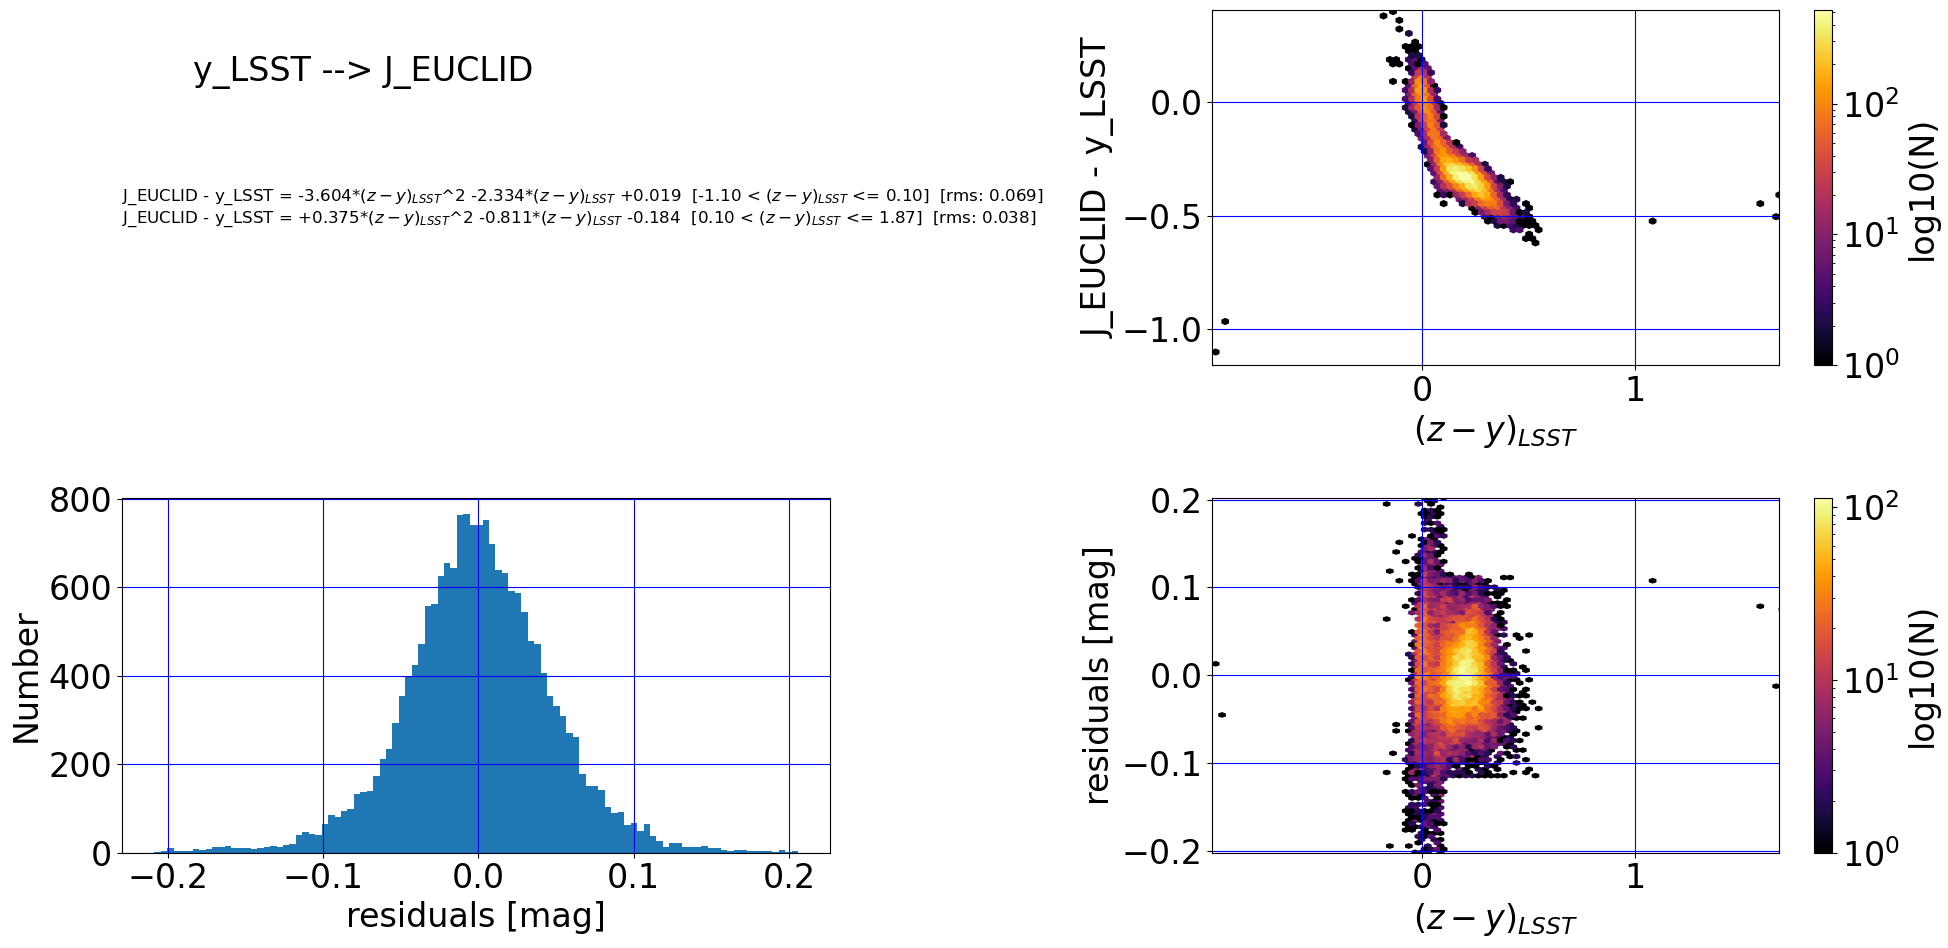

In [48]:
# --- Accumulator for ALL bands ---
qa_rows_all = []

# --- Main loop ---
for band in bandList:

    print("\n\n\n" + "# " * 20)
    print(band)
    print("# " * 20 + "\n")

    magName = band
    magName_match = matchBand_dict[band]
    color_name_1 = color_name_1_dict[band]
    colorLabel_1 = colorLabel_1_dict[band]

    # Create title/names for use in QA plots...
    title = f"{magName_match} --> {magName}"
    dmagName = f"{magName} - {magName_match}"

    # Grab the original version of df from the backup copy...
    df = df_orig.copy()

    # Grab the original version of mask from the backup copy...
    mask = mask_orig.copy()

    # Update dmag column for {$band} - {$band}_match...
    df.loc[:, 'dmag'] = df.loc[:, magName] - df.loc[:, magName_match]

    # Update mask...
    mask1 = (abs(df['dmag']) <= 10.)
    mask2 = ((df[color_name_1] > -3.) & (df[color_name_1] < 6.0))
    mask = mask & mask1 & mask2
    df = df[mask]

    # Calculate number of disjoint branches to fit...
    nbranches = len(color_limits_1_dict[band]) - 1
    if verbose > 0:
        print(band, color_limits_1_dict[band], nbranches)

    # Reset bluest color limit in bluest branch to color1_min
    #  and reddest color limit in reddest branch to color1_max, 
    #  after excluding above mask...
    dftmp = df
    color1_desc = dftmp[color_name_1].describe(percentiles=[0.0001, 0.9999])
    color1_min = math.floor(10*(color1_desc['0.01%']-0.05))/10.
    color1_max = math.ceil(10*(color1_desc['99.99%']+0.05))/10.
    color_limits_1_dict[band][0] = color1_min
    color_limits_1_dict[band][nbranches] = color1_max
    if verbose > 0:
        print(band, color_limits_1_dict[band], nbranches)

    # Iterate, with sigma-clipping...
    color1_list = []
    dmag_list = []
    res_list = []
    mask_list = []
    plot1Text = ''

    for ibranch in range(nbranches):

        print('*********************************')
        print(ibranch, color_limits_1_dict[band][ibranch], color_limits_1_dict[band][ibranch+1])
        print('*********************************')

        mask_branch = ((df[color_name_1] > color_limits_1_dict[band][ibranch]) &
                       (df[color_name_1] <= color_limits_1_dict[band][ibranch+1]))
        df_branch = df[mask_branch].copy()

        # ... and extract dmag's and color1's for this branch...
        dmag_branch = df_branch.loc[:, 'dmag']
        color1_branch = df_branch.loc[:, color_name_1]

        # If there are no valid colors on this branch, continue to next branch...
        if len(color1_branch) < 1:
            continue

        # Perform fit for each disjoint branch...
        print("mask_branch length (before):", len(mask_branch))
        print("dmag_branch length:", len(dmag_branch))
        print("color1_branch length:", len(color1_branch))

        p_branch, perr_branch, color1_branch, dmag_branch, res_branch, stddev_branch = \
            poly_fit_with_sigma_clip(color1_branch, dmag_branch, degree=norder)

        print("mask_branch length (after):", len(mask_branch))

        # NEW:  13 June 2026:
        # Update branch color limits based on clipped data
        lo_new = np.min(color1_branch)
        hi_new = np.max(color1_branch)
        # Store updated limits
        color_limits_1_dict[band][ibranch] = lo_new
        color_limits_1_dict[band][ibranch+1] = hi_new

        # Print coefficients and estimated statistical errors in the coefficients
        for i, (p, perr) in enumerate(zip(p_branch, perr_branch)):
            print(f'p_{len(p_branch)-i-1} = {p:.6f} ± {perr:.6f}')

        # --- Build Markdown table row and add to global list ---
        eq_str = make_eq_str(dmagName, p_branch, colorLabel_1, norder)
        range_str = make_range_str(color_limits_1_dict[band], colorLabel_1, ibranch)
        outputFileName = make_output_filename(
            qaFileBaseName, magName, magName_match, color_name_1, norder
        )
        link_str = f"[link](_static/plots/{outputFileName})"
        title_math = latexify_name(title)
        title_math = title_math.replace("-->", "\\to")
        qa_rows_all.append({
            "Conversion": f"${title_math}$",
            "Transformation Equation": eq_str,
            "RMS": round(stddev_branch, 3),
            "Applicable Color Range": range_str,
            "QA Plot": link_str
        })

        # Keep original plot1Text for QA plots
        if norder == 1:
            plot1Text1 = f"{dmagName} = {p_branch[1]:.3f} + {p_branch[0]:.3f}*{colorLabel_1} " \
                         f"[{color_limits_1_dict[band][ibranch]:.2f} < {colorLabel_1} <= {color_limits_1_dict[band][ibranch+1]:.2f}] " \
                         f"[rms: {stddev_branch:.3f}]"
        elif norder == 2:
            plot1Text1 = f"{dmagName} = {p_branch[2]:.3f} + {p_branch[1]:.3f}*{colorLabel_1} " \
                         f"+ {p_branch[0]:.3f}*{colorLabel_1}^2  " \
                         f"[{color_limits_1_dict[band][ibranch]:.2f} < {colorLabel_1} <= {color_limits_1_dict[band][ibranch+1]:.2f}] " \
                         f"[rms: {stddev_branch:.3f}]"
        else:
            plot1Text1 = ''

        plot1Text1_old = f"{plot1Text}\n{plot1Text1}"
        print(plot1Text1_old)

        plot1Text1 = make_plot_text(
            dmagName, p_branch, colorLabel_1, norder,
            color_limits_1_dict[band], ibranch, stddev_branch
        )
        plot1Text = f"{plot1Text}\n{plot1Text1}"
        print(plot1Text1)
        print(plot1Text)


        # Append branch df and mask to the df_list and mask_list lists, respectively...
        #df_list.append(df_branch.copy())
        #mask_list.append(mask_branch.copy())
        color1_list.append(color1_branch.copy())
        dmag_list.append(dmag_branch.copy())
        res_list.append(res_branch.copy())
        mask_list.append(mask_branch.copy())

    # Concatenate the color1, dmag, res, and mask lists for all the branches...
    color1 = pd.Series(np.concatenate(color1_list))
    dmag = pd.Series(np.concatenate(dmag_list))
    res = pd.Series(np.concatenate(res_list))
    mask = pd.Series(np.concatenate(mask_list))

    # Calculate the standard deviation for the full piecewise fit...
    stddev = res.std()

    # Output best fits to screen...
    if verbose > 0:
        print("")
        print(title)
        print(plot1Text)
        print("")

    # Create QA plots...
    outputFileName = make_output_filename(
        qaFileBaseName, magName, magName_match, color_name_1, norder
    )
    status = transform1ColorQAPlots1a(
        dmag, color1, res, norder, title, plot1Text,
        dmagName, colorLabel_1, stddev, outputFileName
    )

# --- After ALL bands processed: display one big table ---
if qa_rows_all:
    qa_df_all = pd.DataFrame(qa_rows_all)
    # Generate Markdown string (older Pandas: escape removal trick)
    md_table_str = qa_df_all.to_markdown(index=False)
    md_table_str = md_table_str.replace(r'\_', '_')
    print(md_table_str)  # raw Markdown table source

    if write_md_file:
        with open(md_filename, "w") as f:
            f.write(md_table_str)
        print(f"\nMarkdown table written to: {md_filename}")


In [49]:
raise StopExecution

## 12.  Sandbox